# 04 - Stacking ensemble

`StackingClassifier(cv=StratifiedKFold(5))` builds meta-features with `cross_val_predict`: each base pipeline (impute -> SMOTE -> model) is fitted on 4 inner folds and predicts the 5th, so the meta-learner only sees **out-of-fold** probabilities for **real** patients.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
from src.config import load_config
cfg = load_config()
M = cfg.path("paths", "metrics_dir"); F = cfg.path("paths", "figures_dir")
pd.set_option("display.precision", 4); pd.set_option("display.width", 200)
def show(name): display(Image(filename=str(F / name)))

In [2]:
tuned = json.loads((M / 'tuning_results.json').read_text())
print(json.dumps({k: tuned['base_params'][k] for k in tuned['base_params']}, indent=1))
print('meta:', tuned['meta_params'])

{
 "xgboost": {
  "n_estimators": 500,
  "max_depth": 5,
  "learning_rate": 0.014608627448765146,
  "subsample": 0.569912362604018,
  "colsample_bytree": 0.8163669103026254,
  "min_child_weight": 4.760018604883567,
  "reg_alpha": 0.010867230658106504,
  "reg_lambda": 0.0988466112268991,
  "smote_k_neighbors": 8
 },
 "extratrees": {
  "max_depth": 16,
  "n_estimators": 650,
  "min_samples_split": 19,
  "min_samples_leaf": 9,
  "max_features": "log2",
  "smote_k_neighbors": 5
 },
 "catboost": {
  "iterations": 550,
  "depth": 3,
  "learning_rate": 0.013132935817989952,
  "l2_leaf_reg": 12.363572741030406,
  "smote_k_neighbors": 4
 }
}
meta: {'C': 1.2985735596930341, 'l1_ratio': 0.0, 'solver': 'lbfgs'}


## Reconstruct the meta-features live

In [3]:
from src.data.loader import load_split
from src.training.tune import base_oof_meta_features
X_tr, X_te, y_tr, y_te = load_split(cfg)
Z = base_oof_meta_features(tuned['base_params'], X_tr, y_tr, cfg)
Z.assign(y=y_tr).head()

,xgboost,extratrees,catboost,y
row_id,,,,
353,0.0152,0.1274,0.0430,0
711,0.5130,0.4666,0.4913,0
373,0.0485,0.2545,0.1418,0
46,0.5783,0.5037,0.5827,0
682,0.1104,0.3006,0.2328,0


In [4]:
Z.corr()

,xgboost,extratrees,catboost
xgboost,1.0000,0.9280,0.9601
extratrees,0.9280,1.0000,0.9617
catboost,0.9601,0.9617,1.0000


## Base-learner contribution (meta coefficients, drop-one ablation)

In [5]:
sa = json.loads((M / 'stacking_analysis.json').read_text())
display(pd.DataFrame({'coef': sa['meta_coefficients'], 'standardized': sa['meta_standardized_coefficients']}))
display(pd.DataFrame(sa['drop_one']).T)
display(pd.DataFrame(sa['single_base_raw']).T)
print('all bases:', sa['all_bases'])

,coef,standardized
xgboost,0.5707,0.1865
extratrees,2.9460,0.6103
catboost,2.1711,0.6382


,pr_auc,roc_auc,f1@0.5,delta_pr_auc
xgboost,0.7181,0.8413,0.6430,0.0005
extratrees,0.7085,0.8331,0.6452,-0.0090
catboost,0.7129,0.8381,0.6549,-0.0046


,pr_auc,roc_auc,f1@0.5
xgboost,0.6960,0.8238,0.6771
extratrees,0.7232,0.8448,0.6842
catboost,0.7179,0.8361,0.7024


all bases: {'pr_auc': 0.7175246952365057, 'roc_auc': 0.8393457943925234, 'f1@0.5': 0.6395939086294417}


## Stacking vs individual learners

In [6]:
pd.DataFrame(json.loads((M / 'stacking_vs_individual.json').read_text()))

,compared_to,cv_f1@0.5_stack,cv_f1@0.5_other,cv_f1@0.5_rel_pct,cv_pr_auc_stack,cv_pr_auc_other,oof_f1@tuned_stack,oof_f1@tuned_other,test_f1@tuned_stack,test_f1@tuned_other,test_f1@tuned_rel_pct,test_f1@tuned_diff_ci95,test_f1@tuned_p_stack_better,test_f1@0.5_stack,test_f1@0.5_other,test_pr_auc_diff,test_pr_auc_diff_ci95
0,xgboost_smote_tuned,0.6401,0.6607,-3.1067,0.7434,0.7073,0.6971,0.6703,0.6929,0.6667,3.9370,"[-0.023202850675810283, 0.07916953859537589]",0.8335,0.6226,0.6346,-0.0058,"[-0.04529417198241849, 0.03425395632502428]"
1,extratrees_smote_tuned,0.6401,0.6860,-6.6794,0.7434,0.7472,0.6971,0.6980,0.6929,0.6870,0.8574,"[-0.03699121933156593, 0.04683759010095183]",0.5955,0.6226,0.5962,0.0020,"[-0.026343200593848395, 0.03310049853571206]"
2,catboost_smote_tuned,0.6401,0.6893,-7.1313,0.7434,0.7365,0.6971,0.7003,0.6929,0.6615,4.7427,"[-0.007570769052382642, 0.07646834038105299]",0.9475,0.6226,0.5918,0.0160,"[-0.014833782887354052, 0.04784468331699219]"
3,soft_voting_smote_tuned,0.6401,0.6747,-5.1170,0.7434,0.7333,0.6971,0.6904,0.6929,0.6822,1.5748,"[-0.022122038004390977, 0.04374510635855663]",0.7335,0.6226,0.6275,0.0022,"[-0.013509357935964353, 0.022088646188542983]"
4,logistic_regression_nosmote_default,0.6401,0.6461,-0.9175,0.7434,0.7406,0.6971,0.6782,0.6929,0.6306,9.8763,"[-0.006548380260854164, 0.1374856965885268]",0.9635,0.6226,0.5455,0.0355,"[-0.018368086305657227, 0.09588329863774145]"


In [7]:
json.loads((M / 'stacking_fold_wins.json').read_text())

{'xgboost_smote_tuned': {'folds_stack_higher_f1@0.5': 3,
  'folds_stack_higher_pr_auc': 14,
  'n_folds': 15},
 'extratrees_smote_tuned': {'folds_stack_higher_f1@0.5': 1,
  'folds_stack_higher_pr_auc': 6,
  'n_folds': 15},
 'catboost_smote_tuned': {'folds_stack_higher_f1@0.5': 1,
  'folds_stack_higher_pr_auc': 11,
  'n_folds': 15}}

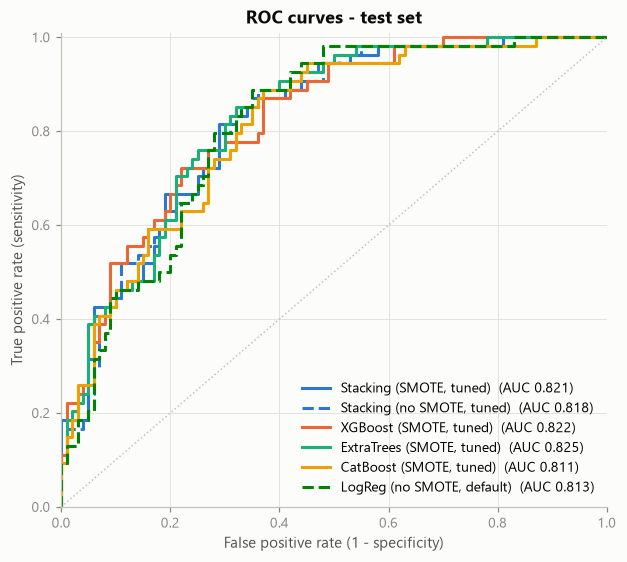

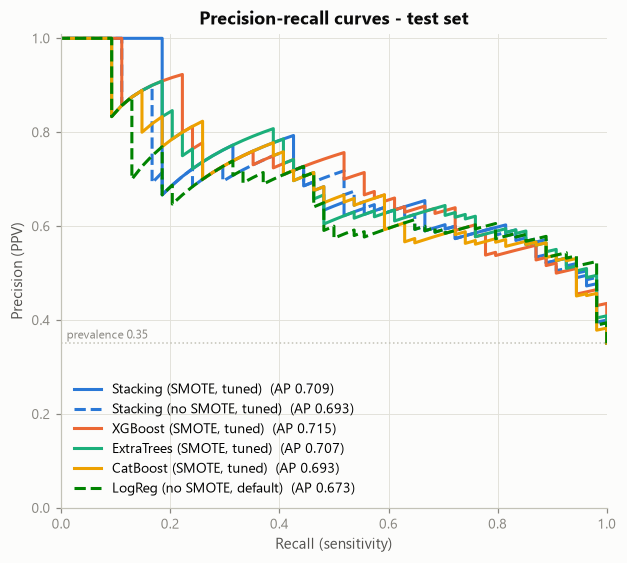

In [8]:
show('test_roc_curves.png'); show('test_pr_curves.png')

## Calibration

,candidate,brier_none,brier_sigmoid,brier_isotonic,chosen
0,logistic_regression_nosmote_default,0.1520,0.1536,0.1557,none
1,logistic_regression_smote_default,0.1621,0.1538,0.1572,sigmoid
2,random_forest_nosmote_default,0.1608,0.1622,0.1639,none
3,random_forest_smote_default,0.1655,0.1641,0.1663,none
4,xgboost_nosmote_default,0.1823,0.1703,0.1713,sigmoid
5,xgboost_smote_default,0.1853,0.1690,0.1713,sigmoid
6,extratrees_nosmote_default,0.1573,0.1546,0.1560,sigmoid
7,extratrees_smote_default,0.1607,0.1552,0.1566,sigmoid
8,catboost_nosmote_default,0.1769,0.1653,0.1689,sigmoid
9,catboost_smote_default,0.1805,0.1653,0.1676,sigmoid


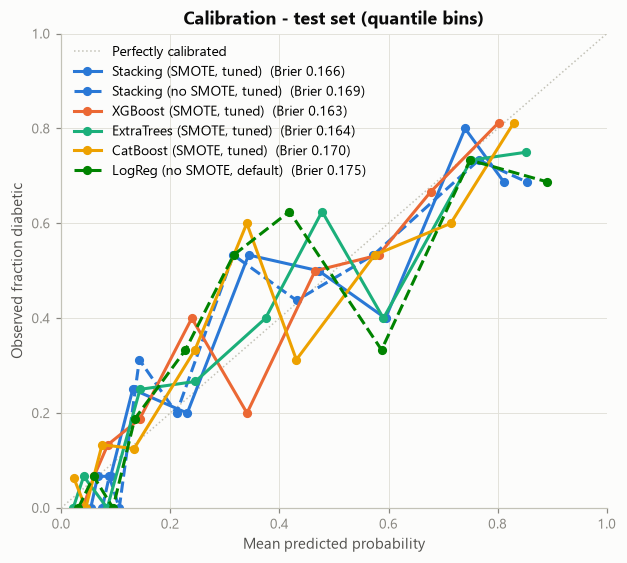

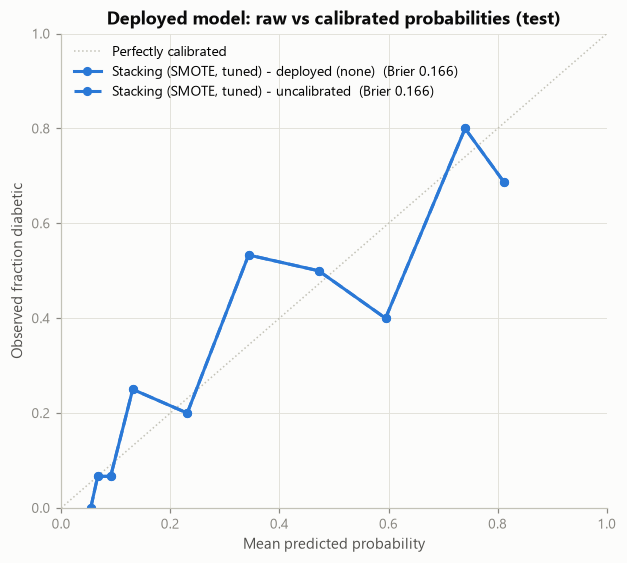

In [9]:
display(pd.read_csv(M / 'calibration_selection.csv'))
show('test_calibration_curves.png'); show('test_calibration_raw_vs_calibrated.png')

## Thresholds (chosen on training OOF predictions)

{'mode': 'fixed', 'deployed_model': 'stacking_smote_tuned', 'best_by_cv': 'extratrees_nosmote_tuned', 'selection_metric': 'pr_auc_mean', 'deployed_cv_score': 0.7433980543301811, 'best_cv_score': 0.7541180227646506, 'note': 'Deployed architecture fixed a priori by the project brief; best_by_cv reported for transparency.'}


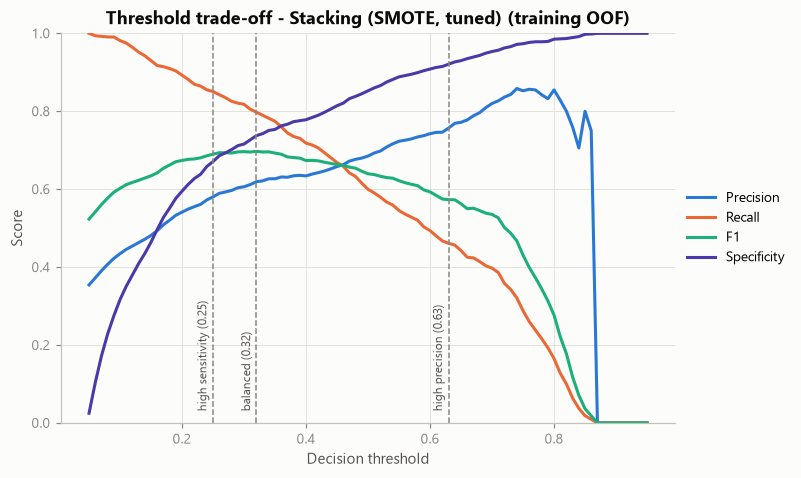

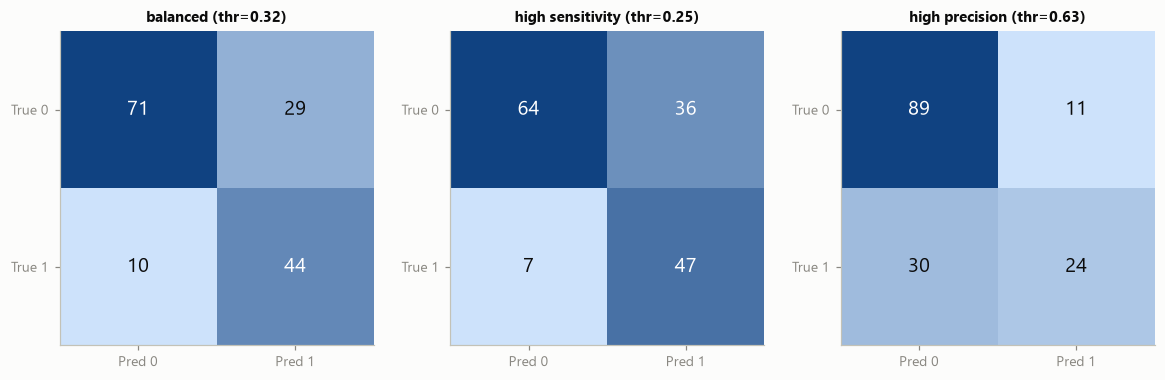

In [10]:
sel = json.loads((M / 'model_selection.json').read_text()); print(sel)
show('threshold_tradeoff_deployed.png'); show('test_confusion_deployed_modes.png')

## Seed stability

In [11]:
pd.read_csv(M / 'stability_summary.csv')

,candidate,pr_auc_mean,pr_auc_std,pr_auc_min,pr_auc_max,roc_auc_mean,roc_auc_std,roc_auc_min,roc_auc_max,f1_mean,...,f1_min,f1_max,recall_mean,recall_std,recall_min,recall_max,brier_mean,brier_std,brier_min,brier_max
0,catboost_smote_tuned,0.7309,0.0131,0.7209,0.7536,0.8412,0.0038,0.8375,0.8474,0.6850,...,0.6751,0.6985,0.7475,0.0152,0.7293,0.7713,0.1590,0.0016,0.1570,0.1615
1,extratrees_smote_tuned,0.7361,0.0060,0.7288,0.7453,0.8458,0.0023,0.8429,0.8488,0.6930,...,0.6865,0.7004,0.7531,0.0131,0.7429,0.7757,0.1681,0.0006,0.1675,0.1689
2,logistic_regression_nosmote_default,0.7311,0.0053,0.7268,0.7401,0.8385,0.0036,0.8342,0.8441,0.6405,...,0.6349,0.6547,0.5746,0.0084,0.5692,0.5890,0.1539,0.0015,0.1515,0.1550
3,stacking_nosmote_tuned,0.7359,0.0107,0.7271,0.7536,0.8435,0.0038,0.8393,0.8496,0.6173,...,0.6079,0.6314,0.5577,0.0155,0.5372,0.5795,0.1538,0.0019,0.1505,0.1553
4,stacking_smote_tuned,0.7333,0.0111,0.7216,0.7513,0.8438,0.0040,0.8397,0.8500,0.6367,...,0.6255,0.6424,0.6018,0.0129,0.5793,0.6114,0.1526,0.0018,0.1495,0.1537
5,xgboost_smote_tuned,0.7118,0.0147,0.6900,0.7248,0.8266,0.0051,0.8204,0.8314,0.6604,...,0.6455,0.6834,0.6971,0.0228,0.6732,0.7339,0.1676,0.0032,0.1641,0.1710
